In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm
import datetime

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil
import matplotlib.pyplot as plt

import utils.functions as fc
import utils.nifti_functions as nfc
import utils.visualization as vis
import utils.util_deep_learning as udl
import utils.util as util

import voxelmorph as vxm


## Visualize data

In [2]:
    
# %matplotlib widget

# data_train = DataLoader(batch_size=3, image_size=(193,229,193), shuffle=False, channels_first=False, image_sufix=pil.INAME_PREPROCESSED, nb_patients=-1, server=True)
# # fc.imgshow_3D("", data_train[0][0][0,0])
# fc.imgshow_3D("", data_train[0][0][0,...,0])

### Validation visualization

In [3]:
def show_generated_image(id, vxm_model, img_size, current_plane=116):
    def fast_resieze(img, img_size):
        return img[:img_size[0], :img_size[1], :img_size[2]]
    
    img_hunt3 = fast_resieze(pil.load_preprocessed_image(3, id, absolute=True)[0], img_size)
    img_hunt4 = fast_resieze(pil.load_preprocessed_image(4, id, absolute=True)[0], img_size)

    img_hunt3 = img_hunt3[:img_size[0], :img_size[1], current_plane]
    img_hunt4 = img_hunt4[:img_size[0], :img_size[1], current_plane]

    # d field
    dfiedl_path = f'{base_path}/test_code/dfield_approach_elastix/images/registrations/{id}_0_DFIELD_0038.nii.gz'
    dfield, _ = nfc.load_nifti(dfiedl_path)
    dfield = dfield[:img_size[0], :img_size[1], current_plane, 0, :2]

    input = np.expand_dims(np.concatenate([np.expand_dims(img_hunt3, axis=-1), dfield], axis=-1), axis=0)

    img_gen_h4 = vxm_model(input, training=False)
    img_gen_h4 = img_gen_h4[0][0, ...,0].numpy()
    img_gen_h4[img_gen_h4 < 0] = 0
    img_gen_h4 = img_gen_h4 / np.max(img_gen_h4)
    return vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4)



# Model training

## Model creation

In [4]:
def create_vxm_model(img_shape):
    # configure unet input shape (concatenation of moving and fixed images)
    ndim = len(img_shape)
    unet_input_features = 3
    inshape = (*img_shape, unet_input_features)

    # configure unet features 
    nb_features = [
        [32, 64, 128, 256],         # encoder features
        [256, 128, 64, 32, 32, 16]  # decoder features
        # [32, 64, 128, 256, 16]
    ]
    # build model
    unet = vxm.networks.Unet(inshape=inshape, nb_features=nb_features)

    if ndim == 2:
        disp_tensor = tf.keras.layers.Conv2D(ndim, kernel_size=3, padding='same', name='disp')(unet.output)
    elif ndim == 3:
        disp_tensor = tf.keras.layers.Conv3D(ndim, kernel_size=3, padding='same', name='disp')(unet.output)
    # def_model = tf.keras.models.Model(unet.inputs, disp_tensor)
    # return def_model

    # warp the moving image with the transformer
    spatial_transformer = vxm.layers.SpatialTransformer(name='transformer')
    moving_image = tf.expand_dims(unet.input[..., 0], axis=-1)
    moved_image_tensor = spatial_transformer([moving_image, disp_tensor])

    outputs = [moved_image_tensor, disp_tensor]
    vxm_model = tf.keras.models.Model(inputs=unet.inputs, outputs=outputs)
    return vxm_model

# model = create_vxm_model((192,224))
# print(model.summary())

### Loss functions

In [5]:
# voxelmorph has a variety of custom loss classes
mse_loss = vxm.losses.MSE().loss
dfield_loss = vxm.losses.Grad('l2').loss

def losses(h4_batch, h4_moved, dfield):
    # mse loss
    loss_mse = mse_loss(h4_batch, h4_moved)

    # gradient loss
    loss_dfield = tf.reduce_mean(dfield_loss(None, dfield))
    loss = loss_mse + 0.05 * loss_dfield
    return loss, loss_mse, loss_dfield

# # usually, we have to balance the two losses by a hyper-parameter
# lambda_param = 0.05
# loss_weights = [1, lambda_param]

In [6]:
# @tf.function
# def train_step(vxm_model, h3_batch, h4_batch, optimizer):
#     with tf.GradientTape() as model_tape:
#         h4_moved, dfield = vxm_model(h3_batch, training=True)
#         loss, loss_mse, loss_dfield = losses(h4_batch, h4_moved, dfield)
        

#     gradients = model_tape.gradient(loss, vxm_model.trainable_variables)
#     optimizer.apply_gradients(zip(gradients, vxm_model.trainable_variables))

#     return loss, loss_mse, loss_dfield

In [7]:
def train_step(vxm_model, h3_batch, h4_batch, optimizer):
    h4_moved, dfield = vxm_model(h3_batch, training=False)

    loss, loss_mse, loss_dfield = losses(h4_batch, h4_moved, dfield)
    h4_moved = h4_moved.numpy() 
    dfield = dfield.numpy() 
    print(h4_moved.min(), h4_moved.max())
    print(dfield.min(), dfield.max())

    return loss, loss_mse, loss_dfield

In [8]:
def load_dfield(data_train, step, img_size, current_plane):
    ids_bacth = data_train.get_ids_by_index(step)
    batch_size = (len(ids_bacth), *img_size, 2)
    batch_dfield = np.empty(batch_size, dtype=np.float32)

    for id in ids_bacth:
        dfiedl_path = f'{base_path}/test_code/dfield_approach_elastix/images/registrations/{id}_0_DFIELD_0038.nii.gz'
        dfield, _ = nfc.load_nifti(dfiedl_path)

        batch_dfield[0, ..., :] = dfield[:img_size[0], :img_size[1], current_plane, 0, :2]
        batch_dfield[0, ..., 0] = util.normalize(batch_dfield[0, ..., 0])
        batch_dfield[0, ..., 1] = util.normalize(batch_dfield[0, ..., 1])
    return batch_dfield

### Training

In [9]:

def train(num_epochs, batch_size):
    # input_shape = (193,229,193)
    input_shape = (192,224,192)
    # input_shape = (64,64,64)
    current_plane = 116

    # ---- Models
    vxm_model = create_vxm_model(input_shape[:2])

    # optimizers
    inital_lr = 1e-2
    optimizer = tf.keras.optimizers.Adam(inital_lr)

    # ---- Data
    server = False
    data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
                                    batch_size=batch_size, 
                                    image_size=input_shape, 
                                    channels_first=False,
                                    shuffle=False, 
                                    nb_patients=10, 
                                    shuffle_before_selecting=False, 
                                    server=server)
    # visualization
    nb_loss = 3
    acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)

    for epoch in range(0,num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # visualize images
        # val_results = show_generated_image("08202", vxm_model, input_shape, current_plane=current_plane)

        # ---- Train
        acum_loss_train.reset()
        progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
        for step, (h3_batch, h4_batch) in enumerate(data_train):
            h3_batch = h3_batch[:,:,:,current_plane,:]
            h4_batch = h4_batch[:,:,:,current_plane,:]

            dfields = load_dfield(data_train, step, input_shape[:2], current_plane)
            h3_dfield = np.concatenate([h3_batch, dfields], axis=-1)
        
            loss, loss_mse, loss_dfield = train_step(vxm_model, h3_dfield, h4_batch, optimizer)
            acum_loss_train.update((loss, loss_mse, loss_dfield))
            losses_text = acum_loss_train.get_progress_bar_text(['loss', 'loss_mse', 'loss_dfield'])

            progress_bar.set_description(desc=losses_text)
            progress_bar.update(1)
        del progress_bar


train(num_epochs=50, batch_size=2)


Epoch 1/50


loss: 0.00768	loss_mse: 0.00747	loss_dfield: 0.00411:  20%|██        | 1/5 [00:07<00:31,  7.86s/it]

0.0 0.87359935
-0.8440524 2.5343044


loss: 0.00831	loss_mse: 0.00771	loss_dfield: 0.01197:  40%|████      | 2/5 [00:11<00:15,  5.17s/it]

0.0 0.87333196
-1.475155 3.2337909


...

loss: inf	loss_mse: 0.01079	loss_dfield: inf:  80%|████████  | 4/5 [00:16<00:03,  3.64s/it]        

0.0 0.8273834
-2.4337033e+33 4.2685485e+33


loss: inf	loss_mse: 0.01286	loss_dfield: inf: 100%|██████████| 5/5 [00:19<00:00,  3.98s/it]


0.0 0.8374227
-2.1636904e+21 4.1287828e+21

Epoch 2/50


Initializing...:   0%|          | 0/5 [00:00<?, ?it/s]


Epoch 1/50


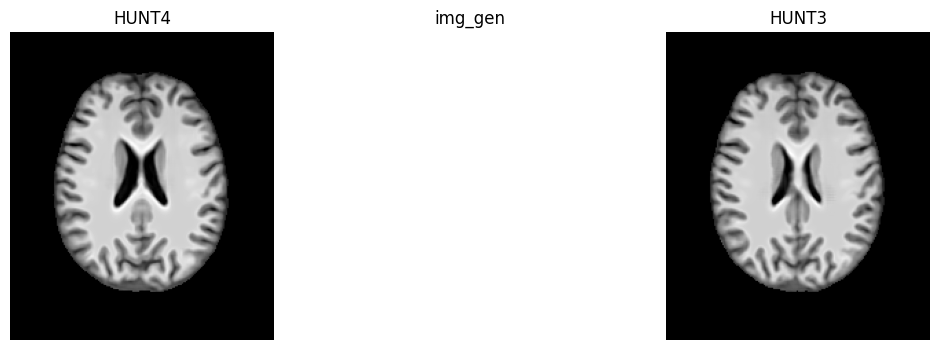

loss: nan	loss_mse: nan	loss_dfield: nan:  20%|██        | 1/5 [00:04<00:17,  4.36s/it]

In [ ]:

# def train(num_epochs, batch_size):
#     # input_shape = (193,229,193)
#     input_shape = (192,224,192)
#     # input_shape = (64,64,64)
#     current_plane = 116

#     # ---- Models
#     vxm_model = create_vxm_model(input_shape[:2])

#     # optimizers
#     inital_lr = 1e-4
#     optimizer = tf.keras.optimizers.Adam(inital_lr)

#     # ---- Data
#     server = False
#     data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
#                                     batch_size=batch_size, 
#                                     image_size=input_shape, 
#                                     channels_first=False,
#                                     shuffle=False, 
#                                     nb_patients=10, 
#                                     shuffle_before_selecting=False, 
#                                     server=server)
#     # visualization
#     nb_loss = 3
#     acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)

#     log_dir=f"{current_path}/models/logs/train"
#     summary_writer = tf.summary.create_file_writer(log_dir)

#     # ---- checkpoint
#     checkpoint_dir = f"{current_path}/models/training_checkpoints/"
#     checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
#     checkpoint = tf.train.Checkpoint(generator_optimizer=optimizer,
#                                     vxm_model=vxm_model)
#     # restore checkpoint
#     checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

#     for epoch in range(0,num_epochs):
#         print(f"\nEpoch {epoch+1}/{num_epochs}")
        
#         # visualize images
#         val_results = show_generated_image("08202", vxm_model, input_shape, current_plane=current_plane)

#         # ---- Train
#         acum_loss_train.reset()
#         progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
#         for step, (h3_batch, h4_batch) in enumerate(data_train):
#             h3_batch = h3_batch[:,:,:,current_plane,:]
#             h4_batch = h4_batch[:,:,:,current_plane,:]

#             dfields = load_dfield(data_train, step, input_shape[:2], current_plane)
#             h3_dfield = np.concatenate([h3_batch, dfields], axis=-1)
        
#             loss, loss_mse, loss_dfield = train_step(vxm_model, h3_dfield, h4_batch, optimizer)
#             acum_loss_train.update((loss, loss_mse, loss_dfield))
#             losses_text = acum_loss_train.get_progress_bar_text(['loss', 'loss_mse', 'loss_dfield'])

#             progress_bar.set_description(desc=losses_text)
#             progress_bar.update(1)
#         del progress_bar

#         # ---- Check points
#         if  epoch > 0 and epoch % 2 == 0:
#             checkpoint.save(file_prefix=checkpoint_prefix)
        
#         # ---- Learning rate
#         # if epoch > 44 and epoch % 22 == 0:
#         if epoch > 10 and epoch % 4 == 0:
#             inital_lr *= 0.5
#             optimizer.learning_rate = inital_lr

#         # ---- tensorboard
#         loss_mean = acum_loss_train.get_mean()
#         with summary_writer.as_default():
#             tf.summary.scalar('loss', loss_mean[0], step=epoch)
#             tf.summary.scalar('loss_mse', loss_mean[0], step=epoch)
#             tf.summary.scalar('loss_dfield', loss_mean[0], step=epoch)

#             # images
#             gen_image = np.expand_dims(np.expand_dims(val_results[2], axis=-1), axis=0)
#             hunt4_vs_gen = np.expand_dims(np.stack([val_results[2], val_results[1], np.zeros_like(val_results[1])], axis=-1), axis=0)
#             tf.summary.image("generated", gen_image, step=epoch)
#             tf.summary.image("R: Gen - G: HUNT4", hunt4_vs_gen, step=epoch)


# train(num_epochs=50, batch_size=2)

In [ ]:
# Sim: 0.00000 	 gen_loss: 0.93415 	 disc_loss: 1.11709: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]
# Sim: 0.00000 	 gen_loss: 1.22538 	 disc_loss: 1.64933: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]